# ST1519 Agile MLOps CA1 — Local development

Run all cells in order: PBI 01 explores the historical data; PBI 02 cleans the complete datasets; PBI 03 prepares a chronological split and fits preprocessing on training data; PBI 06 compares the six baseline models on validation.

**Historical limitation:** PBI 01 originally examined fraud labels across the complete historical dataset before the holdout was defined. Its findings remain here as historical evidence, so the test period was previously examined. Current model development does not construct test features or inspect test outcomes. This notebook is for local development; the team’s PBI 10 automated ETL remains a separate Python pipeline.

# PBI 01 — Exploratory Data Analysis

This notebook explores the three CSV files in the same folder. It reads the raw data without changing it. The label file links orders to customers. The prediction is intended for review before shipment, so feature timing matters.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

customers = pd.read_csv("customers_base.csv", low_memory=False)
orders = pd.read_csv("orders_base.csv")
labels = pd.read_csv("labels_base.csv")

print("Customers:", customers.shape)
print("Orders:", orders.shape)
print("Labels:", labels.shape)

Customers: (901312, 9)
Orders: (949889, 8)
Labels: (950318, 4)


## Dataset overview

The three tables have 901,312 customer rows, 949,889 order rows and 950,318 label rows. Each table's columns, types and summary statistics are shown below. IDs are identifiers, so they are excluded from the descriptive statistics.

In [2]:
customers.info()
display(customers.drop(columns="customer_id").describe(include="all").T)

<class 'pandas.DataFrame'>
RangeIndex: 901312 entries, 0 to 901311
Data columns (total 9 columns):
 #   Column                            Non-Null Count   Dtype  
---  ------                            --------------   -----  
 0   country_code                      901312 non-null  str    
 1   customer_id                       901312 non-null  str    
 2   mobile_verified                   901312 non-null  str    
 3   num_orders_last_50days            901312 non-null  int64  
 4   num_cancelled_orders_last_50days  901312 non-null  int64  
 5   num_refund_orders_last_50days     901312 non-null  int64  
 6   total_payment_last_50days         901312 non-null  float64
 7   num_associated_customers          901312 non-null  int64  
 8   first_order_datetime              900600 non-null  str    
dtypes: float64(1), int64(4), str(4)
memory usage: 92.1 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country_code,901312,7,MY,339134,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mobile_verified,901312,3,True,900681,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_orders_last_50days,901312.0,NaN,NaN,NaN,21.711433,26.281056,0.0,5.0,14.0,29.0,2162.0
num_cancelled_orders_last_50days,901312.0,NaN,NaN,NaN,0.264327,1.005042,0.0,0.0,0.0,0.0,259.0
num_refund_orders_last_50days,901312.0,NaN,NaN,NaN,0.23079,0.8564,0.0,0.0,0.0,0.0,107.0
total_payment_last_50days,901312.0,NaN,NaN,NaN,302.180567,425.800659,0.0,51.471977,164.582166,394.230368,42569.345127
num_associated_customers,901312.0,NaN,NaN,NaN,2.685398,6.36636,1.0,1.0,2.0,3.0,101.0
first_order_datetime,900600,896426,2019-06-13 05:37:00,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
orders.info()
display(orders.drop(columns="order_id").describe(include="all").T)

<class 'pandas.DataFrame'>
RangeIndex: 949889 entries, 0 to 949888
Data columns (total 8 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   country_code       949889 non-null  str    
 1   order_id           949889 non-null  str    
 2   collect_type       949889 non-null  str    
 3   payment_method     928388 non-null  str    
 4   order_value        949889 non-null  float64
 5   num_items_ordered  949888 non-null  float64
 6   refund_value       949889 non-null  float64
 7   order_date         949889 non-null  str    
dtypes: float64(3), str(5)
memory usage: 99.0 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country_code,949889,5,MY,360569,NaN,NaN,NaN,NaN,NaN,NaN,NaN
collect_type,949889,3,Delivery,937730,NaN,NaN,NaN,NaN,NaN,NaN,NaN
payment_method,928388,20,payment on Delivery,312447,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_value,949889.0,NaN,NaN,NaN,6.938344,6.461997,0.0,3.209875,5.509056,8.511989,662.875105
num_items_ordered,949888.0,NaN,NaN,NaN,3.670441,5.012157,1.0,1.0,2.0,4.0,1600.0
refund_value,949889.0,NaN,NaN,NaN,2.236194,3.921423,0.0,0.0,0.93,2.9,518.0
order_date,949889,235,2022/12/03,6423,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
labels.info()
display(labels.drop(columns=["customer_id", "order_id"]).describe(include="all").T)

<class 'pandas.DataFrame'>
RangeIndex: 950318 entries, 0 to 950317
Data columns (total 4 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   country_code  950318 non-null  str  
 1   order_id      950318 non-null  str  
 2   customer_id   950318 non-null  str  
 3   is_fraud      950318 non-null  int64
dtypes: int64(1), str(3)
memory usage: 48.9 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country_code,950318,7,MY,360586,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_fraud,950318.0,NaN,NaN,NaN,0.109967,0.312849,0.0,0.0,0.0,0.0,1.0


## Missing values

The percentages use the number of rows in each table. Payment method is missing for 21,501 orders (2.264%); first order date is missing for 712 customers (0.079%); and one order has a missing item count.

In [5]:
customer_missing = pd.DataFrame({
    "count": customers.isnull().sum(),
    "percent": customers.isnull().mean() * 100
})
display(customer_missing)

,count,percent
country_code,0,0.000000
customer_id,0,0.000000
mobile_verified,0,0.000000
num_orders_last_50days,0,0.000000
num_cancelled_orders_last_50days,0,0.000000
num_refund_orders_last_50days,0,0.000000
total_payment_last_50days,0,0.000000
num_associated_customers,0,0.000000
first_order_datetime,712,0.078996


In [6]:
order_missing = pd.DataFrame({
    "count": orders.isnull().sum(),
    "percent": orders.isnull().mean() * 100
})
display(order_missing)

,count,percent
country_code,0,0.000000
order_id,0,0.000000
collect_type,0,0.000000
payment_method,21501,2.263528
order_value,0,0.000000
num_items_ordered,1,0.000105
refund_value,0,0.000000
order_date,0,0.000000


In [7]:
label_missing = pd.DataFrame({
    "count": labels.isnull().sum(),
    "percent": labels.isnull().mean() * 100
})
display(label_missing)

,count,percent
country_code,0,0.0
order_id,0,0.0
customer_id,0,0.0
is_fraud,0,0.0


## Duplicate records and identifiers

There are no exact duplicate rows. Customer IDs are unique. Orders and labels each contain three repeated order IDs across different countries; this does not mean the records are duplicates. We check the composite keys after normalizing country codes in copies.

In [8]:
print("Duplicate customer rows:", customers.duplicated().sum())
print("Duplicate order rows:", orders.duplicated().sum())
print("Duplicate label rows:", labels.duplicated().sum())
print("Repeated customer IDs:", customers["customer_id"].duplicated().sum())
print("Repeated order IDs in orders:", orders["order_id"].duplicated().sum())
print("Repeated order IDs in labels:", labels["order_id"].duplicated().sum())

Duplicate customer rows: 0


Duplicate order rows: 0
Duplicate label rows: 0
Repeated customer IDs: 0


Repeated order IDs in orders: 3
Repeated order IDs in labels: 3


In [9]:
customers_clean = customers.copy()
orders_clean = orders.copy()
labels_clean = labels.copy()

customers_clean["country_code"] = customers_clean["country_code"].str.strip().str.upper()
orders_clean["country_code"] = orders_clean["country_code"].str.strip().str.upper()
labels_clean["country_code"] = labels_clean["country_code"].str.strip().str.upper()

customer_key = ["country_code", "customer_id"]
order_key = ["country_code", "order_id"]
print("Missing customer keys:", customers_clean[customer_key].isnull().any(axis=1).sum())
print("Missing order keys:", orders_clean[order_key].isnull().any(axis=1).sum())
print("Missing label order keys:", labels_clean[order_key].isnull().any(axis=1).sum())
print("Missing label customer keys:", labels_clean[customer_key].isnull().any(axis=1).sum())
print("Repeated customer composite keys:", customers_clean.duplicated(customer_key).sum())
print("Repeated order composite keys:", orders_clean.duplicated(order_key).sum())
print("Repeated label order composite keys:", labels_clean.duplicated(order_key).sum())

Missing customer keys: 0


Missing order keys: 0
Missing label order keys: 0
Missing label customer keys: 0
Repeated customer composite keys: 0
Repeated order composite keys: 0
Repeated label order composite keys: 0


## Inconsistent values and data quality

Country codes and collection types contain case variations. Mobile verification includes `yes` as well as `True` and `False`; its meaning should be confirmed before mapping it. The tables below show the original values.

In [10]:
print("Customer country codes")
display(customers["country_code"].value_counts(dropna=False))
print("Order country codes")
display(orders["country_code"].value_counts(dropna=False))
print("Label country codes")
display(labels["country_code"].value_counts(dropna=False))

Customer country codes


country_code
MY    339134
PH    289358
PK    151877
TH     72509
BD     48044
pk       225
my       165
Name: count, dtype: int64

Order country codes


country_code
MY    360569
PH    281211
PK    184822
TH     63727
BD     59560
Name: count, dtype: int64

Label country codes


country_code
MY    360586
PH    281239
PK    184840
TH     63788
BD     59564
ph       180
my       121
Name: count, dtype: int64

In [11]:
print("Mobile verification")
display(customers["mobile_verified"].astype("string").value_counts(dropna=False))
print("Collection type")
display(orders["collect_type"].value_counts(dropna=False))
print("Payment method")
display(orders["payment_method"].value_counts(dropna=False))

Mobile verification


mobile_verified
True     900681
False       466
yes         165
Name: count, dtype: int64[pyarrow]

Collection type


collect_type
Delivery    937730
pickup       12074
delivery        85
Name: count, dtype: int64

Payment method


payment_method
payment on Delivery       312447
cybersource               135418
online banking            124880
credit card               114242
antfinancial gcash        102657
generic creditcard         72319
balance                    25936
NaN                        21501
antfinancial bkash         17889
antfinancial truemoney      9294
boost wallet                6088
jazzcash wallet             2509
invoice                     1963
adyen hpp molpay             837
no payment                   670
cybersource applepay         584
paypal                       367
on Delivery                  160
Online Banking               103
payment on delivery           20
xendit directdebit             5
Name: count, dtype: int64

Dates are parsed only for checking: missing dates and invalid nonmissing dates are counted separately. Neither date column contains invalid nonmissing values. Refunds exceed the order value in 199,687 orders; this needs investigation, since adjustments or other business rules may explain it.

In [12]:
first_date = pd.to_datetime(customers["first_order_datetime"], errors="coerce", format="mixed")
order_date = pd.to_datetime(orders["order_date"], errors="coerce", format="mixed")

print("Invalid nonmissing customer dates:", (customers["first_order_datetime"].notna() & first_date.isna()).sum())
print("Customer date range:", first_date.min(), "to", first_date.max())
print("Invalid nonmissing order dates:", (orders["order_date"].notna() & order_date.isna()).sum())
print("Order date range:", order_date.min(), "to", order_date.max())

Invalid nonmissing customer dates: 0
Customer date range: 2012-03-25 12:53:43 to 2023-05-10 20:59:37
Invalid nonmissing order dates: 0
Order date range: 2022-11-12 00:00:00 to 2023-05-11 00:00:00


In [13]:
print("Negative customer values")
display((customers.select_dtypes(include="number") < 0).sum())
print("Negative order values")
display((orders.select_dtypes(include="number") < 0).sum())
print("Refund exceeds order value:", (orders["refund_value"] > orders["order_value"]).sum())
print("Cancellations exceed orders:", (customers["num_cancelled_orders_last_50days"] > customers["num_orders_last_50days"]).sum())
print("Refunded orders exceed orders:", (customers["num_refund_orders_last_50days"] > customers["num_orders_last_50days"]).sum())

Negative customer values


num_orders_last_50days              0
num_cancelled_orders_last_50days    0
num_refund_orders_last_50days       0
total_payment_last_50days           0
num_associated_customers            0
dtype: int64

Negative order values


order_value          0
num_items_ordered    0
refund_value         0
dtype: int64

Refund exceeds order value: 199687
Cancellations exceed orders: 0
Refunded orders exceed orders: 0


## Relationships and join checks

`country_code` plus `order_id` is the order key; `country_code` plus `customer_id` is the customer key. These checks reject missing and duplicate keys before merging. `validate` prevents accidental many-to-many joins. Outer joins show unmatched records on both sides; customers without labels may simply have no orders in this extract.

In [14]:
assert not customers_clean[customer_key].isnull().any().any()
assert not orders_clean[order_key].isnull().any().any()
assert not labels_clean[order_key].isnull().any().any()
assert not labels_clean[customer_key].isnull().any().any()
assert not customers_clean.duplicated(customer_key).any()
assert not orders_clean.duplicated(order_key).any()
assert not labels_clean.duplicated(order_key).any()

In [15]:
order_links = labels_clean.merge(
    orders_clean, on=order_key, how="outer", indicator=True, validate="one_to_one"
)
print("Labels and orders")
display(order_links["_merge"].value_counts())

Labels and orders


_merge
both          949874
left_only        444
right_only        15
Name: count, dtype: int64

In [16]:
customer_links = labels_clean.merge(
    customers_clean, on=customer_key, how="outer", indicator=True, validate="many_to_one"
)
print("Labels and customers")
display(customer_links["_merge"].value_counts())

Labels and customers


_merge
both          950304
right_only    279054
left_only         14
Name: count, dtype: int64

The order join finds 949,874 matches, 444 labels without orders and 15 orders without labels. The customer join finds 14 label rows without customers and 279,054 customers without label records. The table below compares country codes only for unambiguous IDs; repeated order IDs across countries must not be mistaken for conflicts.

In [17]:
unique_labels = labels_clean[~labels_clean["order_id"].duplicated(keep=False)]
unique_orders = orders_clean[~orders_clean["order_id"].duplicated(keep=False)]
order_countries = unique_labels[["order_id", "country_code"]].merge(
    unique_orders[["order_id", "country_code"]], on="order_id",
    suffixes=("_label", "_order"), validate="one_to_one"
)
print("Order country conflicts:", (order_countries["country_code_label"] != order_countries["country_code_order"]).sum())

Order country conflicts: 0


In [18]:
customer_countries = labels_clean[["customer_id", "country_code"]].merge(
    customers_clean[["customer_id", "country_code"]], on="customer_id",
    suffixes=("_label", "_customer"), validate="many_to_one"
)
print("Customer country conflicts:", (customer_countries["country_code_label"] != customer_countries["country_code_customer"]).sum())
print("Order IDs with different fraud labels across countries:", labels_clean.groupby("order_id")["is_fraud"].nunique().gt(1).sum())

Customer country conflicts: 0
Order IDs with different fraud labels across countries: 1


Country conflicts on unambiguous IDs are zero after normalization. One repeated order ID has different labels in different countries; it represents different composite keys, not necessarily conflicting labels.

In [19]:
joined = labels_clean.merge(
    orders_clean, on=order_key, how="left", indicator="order_match", validate="one_to_one"
)
joined = joined.merge(
    customers_clean, on=customer_key, how="left", indicator="customer_match", validate="many_to_one"
)
assert len(joined) == len(labels_clean)
print("Label rows retained:", len(joined))

Label rows retained: 950318


## Numerical distributions and outliers

The table uses all available values. Skewness shows that several counts and amounts have long right tails. The 1.5 × IQR rule flags possible outliers; for a zero IQR it flags every positive value, so flags should not automatically be removed. Histograms below show values up to the 99th percentile for readability, excluding the remaining upper tail from the charts only.

In [20]:
customer_numbers = customers.select_dtypes(include="number")
order_numbers = orders.select_dtypes(include="number")
print("Customer statistics")
display(customer_numbers.describe().T)
print("Customer skewness")
display(customer_numbers.skew())
print("Order statistics")
display(order_numbers.describe().T)
print("Order skewness")
display(order_numbers.skew())

Customer statistics


,count,mean,std,min,25%,50%,75%,max
num_orders_last_50days,901312.0,21.711433,26.281056,0.0,5.000000,14.000000,29.000000,2162.000000
num_cancelled_orders_last_50days,901312.0,0.264327,1.005042,0.0,0.000000,0.000000,0.000000,259.000000
num_refund_orders_last_50days,901312.0,0.230790,0.856400,0.0,0.000000,0.000000,0.000000,107.000000
total_payment_last_50days,901312.0,302.180567,425.800659,0.0,51.471977,164.582166,394.230368,42569.345127
num_associated_customers,901312.0,2.685398,6.366360,1.0,1.000000,2.000000,3.000000,101.000000


Customer skewness


num_orders_last_50days               5.419459
num_cancelled_orders_last_50days    54.998623
num_refund_orders_last_50days       17.515436
total_payment_last_50days            8.676179
num_associated_customers            12.478703
dtype: float64

Order statistics


,count,mean,std,min,25%,50%,75%,max
order_value,949889.0,6.938344,6.461997,0.0,3.209875,5.509056,8.511989,662.875105
num_items_ordered,949888.0,3.670441,5.012157,1.0,1.000000,2.000000,4.000000,1600.000000
refund_value,949889.0,2.236194,3.921423,0.0,0.000000,0.930000,2.900000,518.000000


Order skewness


order_value           6.620409
num_items_ordered    41.042020
refund_value          8.409762
dtype: float64

In [21]:
customer_q1 = customer_numbers.quantile(0.25)
customer_q3 = customer_numbers.quantile(0.75)
customer_iqr = customer_q3 - customer_q1
customer_outliers = (customer_numbers.lt(customer_q1 - 1.5 * customer_iqr) |
                     customer_numbers.gt(customer_q3 + 1.5 * customer_iqr))
display(pd.DataFrame({"IQR": customer_iqr, "possible outliers": customer_outliers.sum()}))

,IQR,possible outliers
num_orders_last_50days,24.000000,53579
num_cancelled_orders_last_50days,0.000000,151945
num_refund_orders_last_50days,0.000000,128372
total_payment_last_50days,342.758391,63144
num_associated_customers,2.000000,39178


In [22]:
order_q1 = order_numbers.quantile(0.25)
order_q3 = order_numbers.quantile(0.75)
order_iqr = order_q3 - order_q1
order_outliers = (order_numbers.lt(order_q1 - 1.5 * order_iqr) |
                  order_numbers.gt(order_q3 + 1.5 * order_iqr))
display(pd.DataFrame({"IQR": order_iqr, "possible outliers": order_outliers.sum()}))

,IQR,possible outliers
order_value,5.302114,56798
num_items_ordered,3.000000,69852
refund_value,2.900000,71069


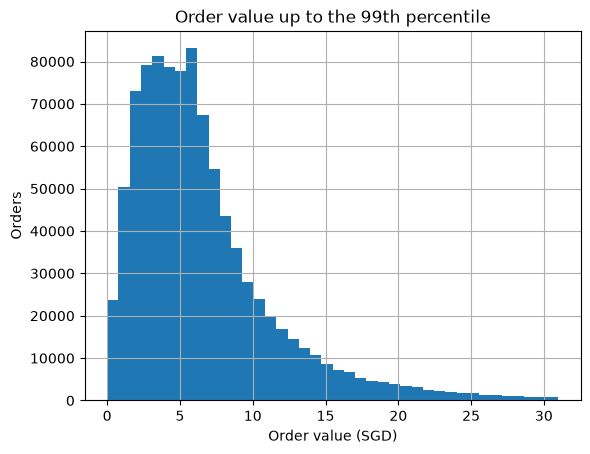

In [23]:
orders["order_value"].loc[orders["order_value"] <= orders["order_value"].quantile(0.99)].hist(bins=40)
plt.title("Order value up to the 99th percentile")
plt.xlabel("Order value (SGD)")
plt.ylabel("Orders")
plt.show()

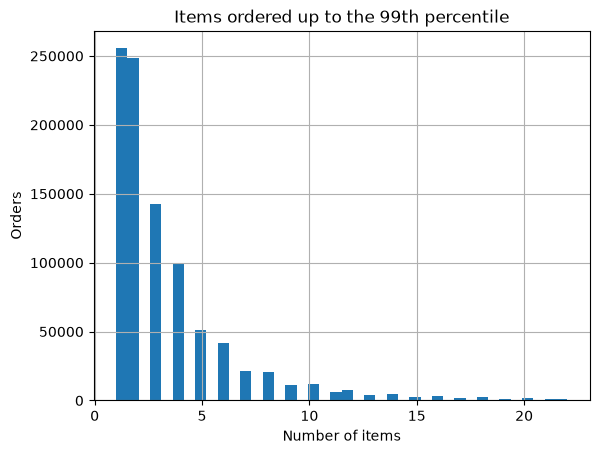

In [24]:
orders["num_items_ordered"].loc[orders["num_items_ordered"] <= orders["num_items_ordered"].quantile(0.99)].hist(bins=40)
plt.title("Items ordered up to the 99th percentile")
plt.xlabel("Number of items")
plt.ylabel("Orders")
plt.show()

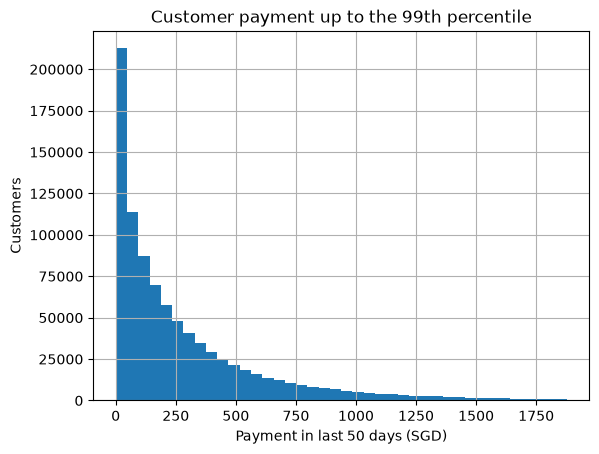

In [25]:
customers["total_payment_last_50days"].loc[customers["total_payment_last_50days"] <= customers["total_payment_last_50days"].quantile(0.99)].hist(bins=40)
plt.title("Customer payment up to the 99th percentile")
plt.xlabel("Payment in last 50 days (SGD)")
plt.ylabel("Customers")
plt.show()

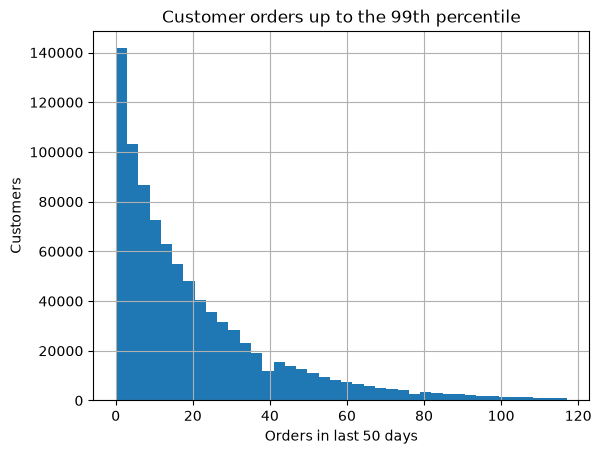

In [26]:
customers["num_orders_last_50days"].loc[customers["num_orders_last_50days"] <= customers["num_orders_last_50days"].quantile(0.99)].hist(bins=40)
plt.title("Customer orders up to the 99th percentile")
plt.xlabel("Orders in last 50 days")
plt.ylabel("Customers")
plt.show()

## Fraud distribution and patterns

There are 104,504 fraud labels (11.0%) and 845,814 non-fraud labels (89.0%). The following patterns use only matched labeled orders, with group counts shown in tables. They are associations, not proof of cause. Refund and customer history are not used in the charts because their availability at prediction time is uncertain.

,count,percent
is_fraud,,
0,845814,89.00326
1,104504,10.99674


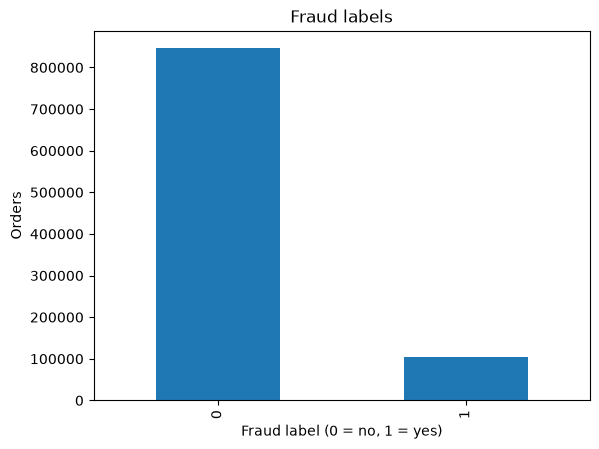

In [27]:
fraud_counts = labels["is_fraud"].value_counts(dropna=False).sort_index()
fraud_percent = labels["is_fraud"].value_counts(dropna=False, normalize=True).sort_index() * 100
display(pd.DataFrame({"count": fraud_counts, "percent": fraud_percent}))
fraud_counts.plot.bar()
plt.title("Fraud labels")
plt.xlabel("Fraud label (0 = no, 1 = yes)")
plt.ylabel("Orders")
plt.show()

Matched labeled orders: 949874


,orders,fraud_rate
collection,,
delivery,937800,0.107637
pickup,12074,0.288223


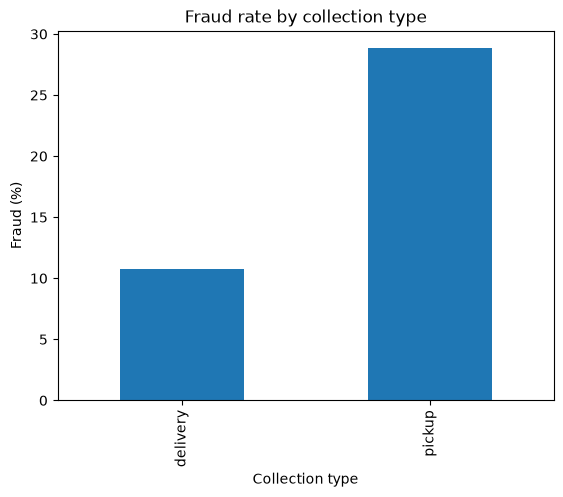

In [28]:
matched = joined[(joined["order_match"] == "both") & (joined["is_fraud"].isin([0, 1]))].copy()
print("Matched labeled orders:", len(matched))
matched["collection"] = matched["collect_type"].str.strip().str.lower().fillna("missing")
collection_rates = matched.groupby("collection")["is_fraud"].agg(["size", "mean"])
collection_rates.columns = ["orders", "fraud_rate"]
display(collection_rates)
(collection_rates["fraud_rate"] * 100).plot.bar()
plt.title("Fraud rate by collection type")
plt.xlabel("Collection type")
plt.ylabel("Fraud (%)")
plt.show()

,orders,fraud_rate
value_band,,
"(-0.001, 2.737]",189979,0.138447
"(2.737, 4.58]",189971,0.106758
"(4.58, 6.447]",189974,0.091312
"(6.447, 9.584]",189975,0.090296
"(9.584, 662.875]",189975,0.122848


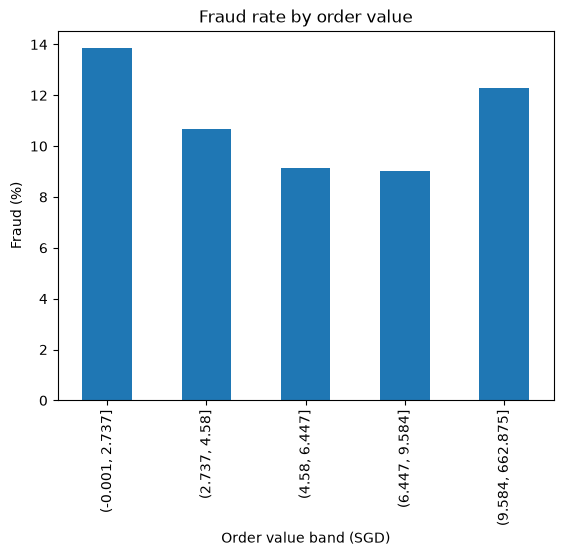

In [29]:
matched["value_band"] = pd.qcut(matched["order_value"], 5, duplicates="drop")
value_rates = matched.groupby("value_band", observed=True)["is_fraud"].agg(["size", "mean"])
value_rates.columns = ["orders", "fraud_rate"]
display(value_rates)
(value_rates["fraud_rate"] * 100).plot.bar()
plt.title("Fraud rate by order value")
plt.xlabel("Order value band (SGD)")
plt.ylabel("Fraud (%)")
plt.show()

## Data quality recommendations and limitations

- **PBI 02:** Standardize country and collection-type case on copies. Confirm whether `yes` means true. Investigate missing values, unmatched keys and refund amounts greater than order values. Keep missing indicators and do not invent missing labels. Do not deduplicate using order ID alone.
- **PBI 03:** Confirm which fields exist at the pre-shipment prediction time. Exclude the fraud label, refund value, refund-related history and snapshot aggregates that may contain later information until their timing is verified. Build customer history using only information available before each order.
- Consider log transformations for skewed nonnegative values, robust scaling and categorical encoding. Fit imputation, encoding, scaling and any resampling on training data only. Investigate outliers instead of automatically deleting them.
- Fraud is the minority class. Report precision and recall as well as accuracy, and consider class weighting or training-only resampling. Use time-aware validation and check for repeated customers across splits.

The quality register and findings summary in `reports/` give the affected counts and recommendations. These findings describe the historical files and are not evidence of causation.

The EDA above is complete. The following sections call the reusable modules on the same loaded data. Large temporary EDA tables are released before the full-data cleaning and model stages.

In [30]:
import gc
import seaborn as sns
from IPython.display import display, Image

from src.data_cleaning import clean_customers, clean_orders, clean_labels, check_relationships
from src.feature_engineering import prepare_training_data, fit_preprocessor, INPUT_FEATURES
from src.train_hq import load_finalized_results

del customers_clean, orders_clean, labels_clean
del order_links, customer_links, order_countries, customer_countries
del unique_labels, unique_orders, joined, matched
del customer_numbers, order_numbers, customer_outliers, order_outliers
gc.collect()
print("Historical EDA complete; starting reusable cleaning.")

Historical EDA complete; starting reusable cleaning.


## PBI 02 — Full-data cleaning

The input files are never modified. The functions return retained rows, rejected original rows and cleaning reports. Issue counts may overlap and are measured before rejection. Validation of the source schema and label values is part of data cleaning; it is not a test-set metric or a model-selection step.

In [31]:
print("Cleaning customers...")
customers_clean, customers_rejected, customer_report = clean_customers(customers)
print("Cleaning orders...")
orders_clean, orders_rejected, order_report = clean_orders(orders)
print("Cleaning labels...")
labels_clean, labels_rejected, label_report = clean_labels(labels)
print("Cleaning complete.")

Cleaning customers...


Cleaning orders...


Cleaning labels...
Cleaning complete.


In [32]:
cleaning_reports = pd.DataFrame([customer_report, order_report, label_report],
                                index=["customers", "orders", "labels"])
display(cleaning_reports[["received", "changed", "rejected", "retained",
                          "exact_duplicate_rows", "conflicting_key_rows", "invalid_key_rows"]])
print("Customer quality checks:")
display(pd.Series(customer_report["issues"], name="count"))
print("Order quality checks:")
display(pd.Series(order_report["issues"], name="count"))
print("Label quality checks:")
display(pd.Series(label_report["issues"], name="count"))

,received,changed,rejected,retained,exact_duplicate_rows,conflicting_key_rows,invalid_key_rows
customers,901312,555,0,901312,0,0,0
orders,949889,949889,0,949889,0,0,0
labels,950318,301,0,950318,0,0,0


Customer quality checks:


mobile_verified_unrecognized                165
num_orders_last_50days_invalid                0
num_cancelled_orders_last_50days_invalid      0
num_refund_orders_last_50days_invalid         0
num_associated_customers_invalid              0
total_payment_last_50days_invalid             0
first_order_datetime_invalid                  0
cancellations_exceed_orders                   0
refunds_exceed_orders                         0
Name: count, dtype: int64

Order quality checks:


order_value_invalid                0
num_items_ordered_invalid          0
refund_value_invalid               0
order_date_invalid                 0
refund_exceeds_order_value    199687
Name: count, dtype: int64

Label quality checks:


invalid_or_missing_fraud_labels    0
Name: count, dtype: int64

In [33]:
relationships = check_relationships(customers_clean, orders_clean, labels_clean)
print("Labels and orders:")
display(pd.Series(relationships["order_counts"], name="rows"))
print("Labels and customers:")
display(pd.Series(relationships["customer_counts"], name="rows"))

Labels and orders:


both          949874
left_only        444
right_only        15
Name: rows, dtype: int64

Labels and customers:


both          950304
right_only    279054
left_only         14
Name: rows, dtype: int64

## PBI 03 — Chronological split and preprocessing

The same-date 70/15/15 split comes from the shared feature module. No test feature frame or test labels are returned to this notebook. The table shows dataset sizes and dates only. The preprocessor is fitted on training and reused for validation.

In [34]:
print("Preparing the chronological split...")
x_train, y_train, x_val, y_val, x_test, y_test, split = prepare_training_data(
    customers_clean, orders_clean, labels_clean, include_test=False, include_training_dates=True
)
assert x_test is None and y_test is None
train_dates = split.pop("training_dates")  # metadata only, never a model feature
split_table = pd.DataFrame({
    "rows": [split["training_rows"], split["validation_rows"], split["test_rows"]],
    "first_date": [split["train_first_date"], split["validation_first_date"], split["test_first_date"]],
    "last_date": [split["train_last_date"], split["validation_last_date"], split["test_last_date"]]
}, index=["training", "validation", "test (held out)"])
display(split_table)
print("Input features:", INPUT_FEATURES)

Preparing the chronological split...


,rows,first_date,last_date
training,660773,2022-11-12,2023-03-14
validation,144978,2023-03-15,2023-04-13
test (held out),144123,2023-04-14,2023-05-11


Input features: ['order_value', 'num_items_ordered', 'order_weekday', 'order_month', 'country_code', 'collect_type', 'payment_method']


In [35]:
print("Fitting preprocessing on training data only...")
preprocessor = fit_preprocessor(x_train)
print("Training rows:", len(x_train))
print("Validation rows:", len(x_val))
print("Transformed features:", len(preprocessor.get_feature_names_out()))
print("The benchmark will transform training and validation once using this fitted preprocessor.")

Fitting preprocessing on training data only...


Training rows: 660773
Validation rows: 144978
Transformed features: 31
The benchmark will transform training and validation once using this fitted preprocessor.


## PBI 06 — Historical validation benchmark

The six baselines below are the original recorded validation results, not new training runs. All used the same split and threshold 0.5. Fraud-class F1 determines the ranking. Historical artifacts are required; the notebook stops with a clear error if they are unavailable.

In [36]:
from pathlib import Path

local_uri = "sqlite:///" + str((Path("artifacts/mlflow/mlflow.db")).resolve())
print("Loading the 15 original PBI 06 versions and their trial evidence...")
groups, inner_trials, advanced_trials = load_finalized_results(split, tracking_uri=local_uri)
results = groups["baseline"]
comparison = pd.DataFrame(results).drop(columns="parameters")
display(comparison)
print("Historical local MLflow store:", local_uri)

Loading the 15 original PBI 06 versions and their trial evidence...


,model,version,threshold,f1,precision,recall,average_precision,roc_auc,accuracy,tn,fp,fn,tp,false_positive_rate,training_seconds,prediction_seconds,run_id
0,catboost,baseline,0.5,0.444263,0.309565,0.786474,0.468765,0.822419,0.732090,90612,34626,4215,15525,0.276482,1.840751,0.005115,59a72ead8d34483ea1f82644b4511d55
1,random_forest,baseline,0.5,0.441067,0.305481,0.793060,0.475494,0.823670,0.726324,89646,35592,4085,15655,0.284195,2.372368,0.036476,25bb1427c3b647668c8037fc761e88a9
2,xgboost,baseline,0.5,0.440974,0.305490,0.792401,0.475565,0.823769,0.726448,89677,35561,4098,15642,0.283947,0.638068,0.037345,0aeac7b9725849fead64c77b5705b0bb
3,lightgbm,baseline,0.5,0.440884,0.305396,0.792452,0.478404,0.824276,0.726331,89659,35579,4097,15643,0.284091,0.603209,0.064812,91db7fa7fc694ce3952c515cc386405a
4,hist_gradient_boosting,baseline,0.5,0.439756,0.304465,0.791439,0.473654,0.822623,0.725427,89548,35690,4117,15623,0.284977,2.386679,0.068264,f6e01df787d14eb3b7271f1dc047711a
5,logistic_regression,baseline,0.5,0.424602,0.290647,0.787589,0.434044,0.810814,0.709356,87294,37944,4193,15547,0.302975,2.452170,0.001048,d7b938d37c054cea9f9a8df611bdecfd


Historical local MLflow store: sqlite:////Users/hq/Documents/Study materials/y2s2/mlops/agilemlops-ca1/artifacts/mlflow/mlflow.db


In [37]:
parameters = pd.DataFrame({result["model"]: result["parameters"] for result in results}).T
display(parameters)

,iterations,learning_rate,depth,thread_count,random_seed,verbose,allow_writing_files,bootstrap,ccp_alpha,class_weight,...,scoring,tol,validation_fraction,C,dual,fit_intercept,intercept_scaling,l1_ratio,penalty,solver
catboost,80,0.1,5,4,42,False,False,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
random_forest,NaN,NaN,NaN,NaN,NaN,0,NaN,True,0.0,balanced,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
xgboost,NaN,0.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lightgbm,NaN,0.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hist_gradient_boosting,NaN,0.1,NaN,NaN,NaN,0,NaN,NaN,NaN,None,...,loss,0.0,0.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
logistic_regression,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,balanced,...,NaN,0.0001,NaN,1.0,False,True,1,0.0,deprecated,lbfgs


### Validation confusion matrices

Rows are actual outcomes; columns are predicted outcomes. 1 means fraud.

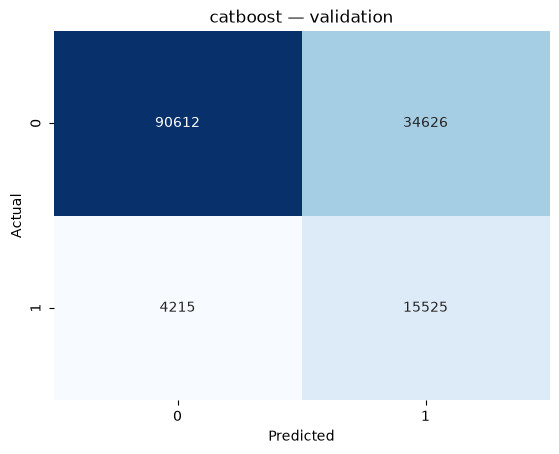

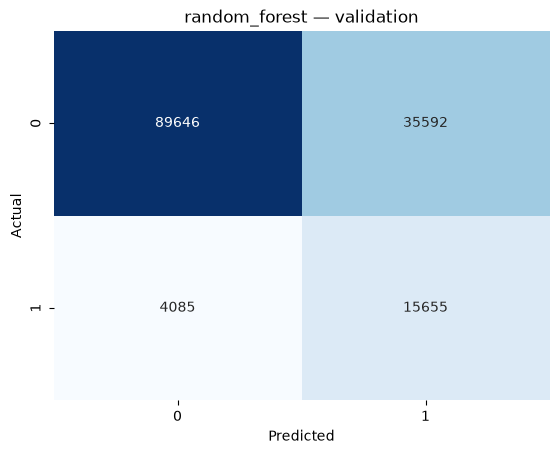

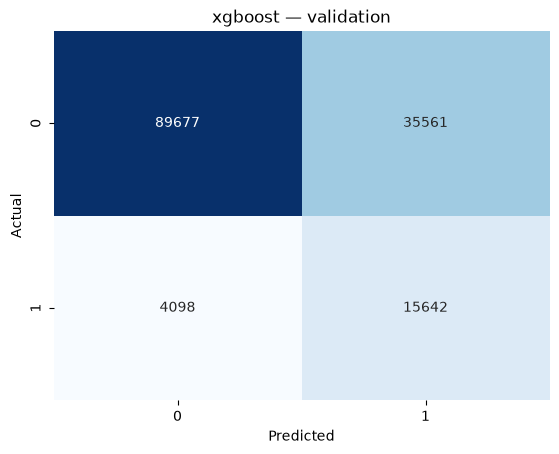

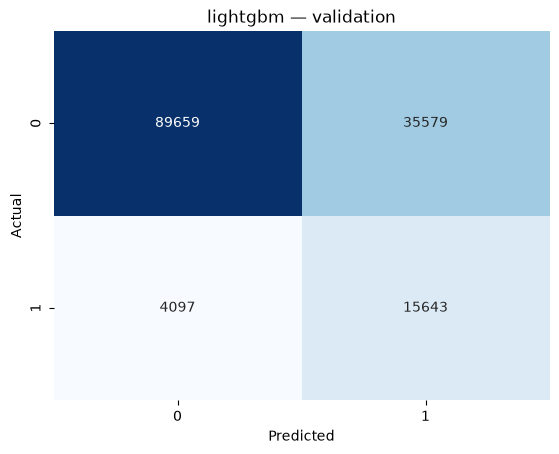

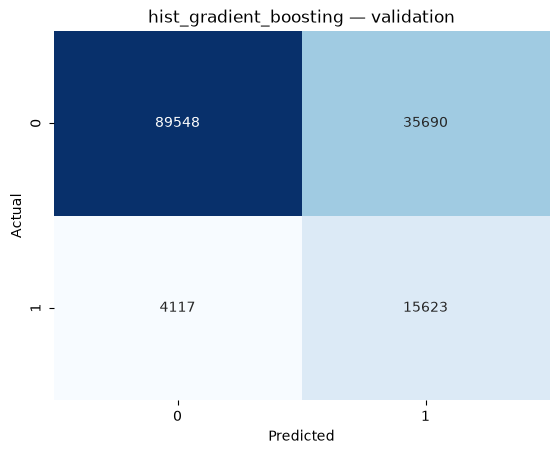

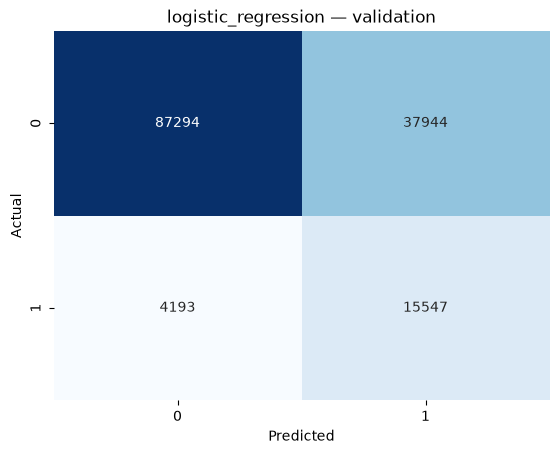

In [38]:
for result in results:
    matrix = [[result["tn"], result["fp"]], [result["fn"], result["tp"]]]
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(result["model"] + " — validation")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

### Model comparison

Higher validation fraud F1 ranks first. Precision and recall should also be considered alongside operational review capacity.

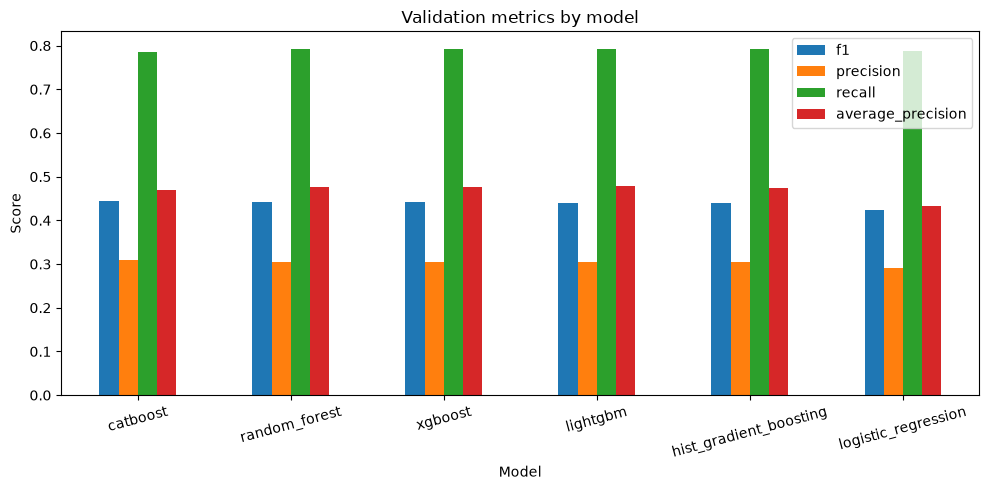

In [39]:
comparison.set_index("model")[["f1", "precision", "recall", "average_precision"]].plot.bar(figsize=(10, 5))
plt.title("Validation metrics by model")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Fraud detection versus false alarms

False-positive rate is the fraction of non-fraud orders incorrectly flagged. Higher recall detects more fraud; lower false-positive rate reduces unnecessary reviews.

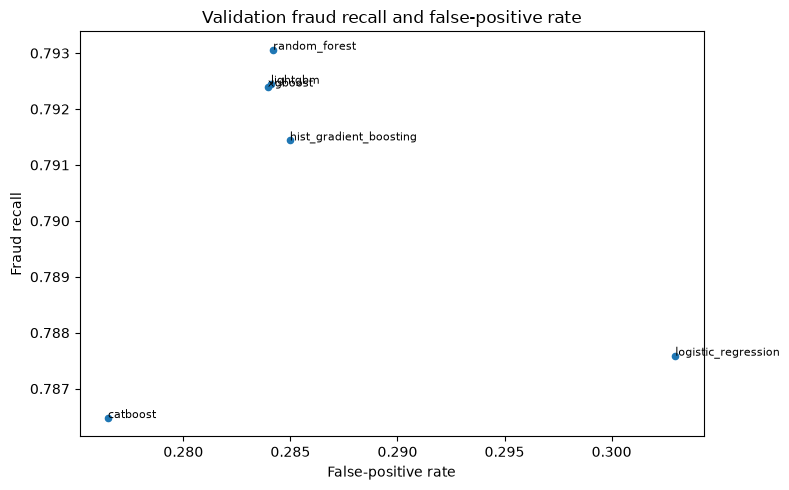

In [40]:
comparison.plot.scatter(x="false_positive_rate", y="recall", figsize=(8, 5))
for _, row in comparison.iterrows():
    plt.annotate(row["model"], (row["false_positive_rate"], row["recall"]), fontsize=8)
plt.title("Validation fraud recall and false-positive rate")
plt.xlabel("False-positive rate")
plt.ylabel("Fraud recall")
plt.tight_layout()
plt.show()

### Precision–recall curves and local MLflow

Curves and run artifacts are stored in the local project MLflow backend. Start the local UI from the project folder with `mlflow ui --backend-store-uri sqlite:///artifacts/mlflow/mlflow.db`, then open `http://127.0.0.1:5000`. This notebook explicitly selects the local store.

catboost MLflow run: 59a72ead8d34483ea1f82644b4511d55


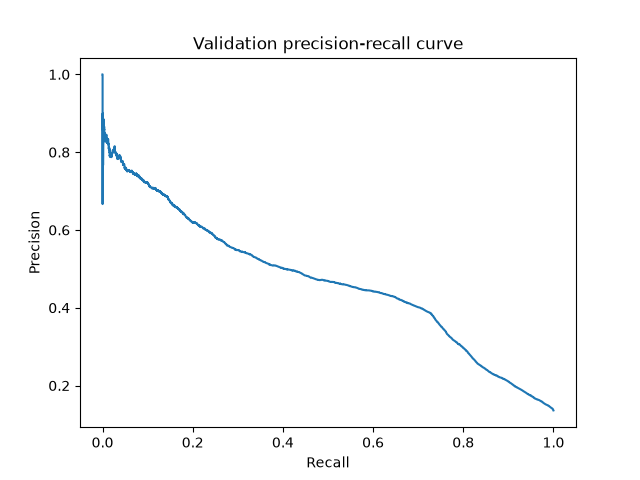

random_forest MLflow run: 25bb1427c3b647668c8037fc761e88a9


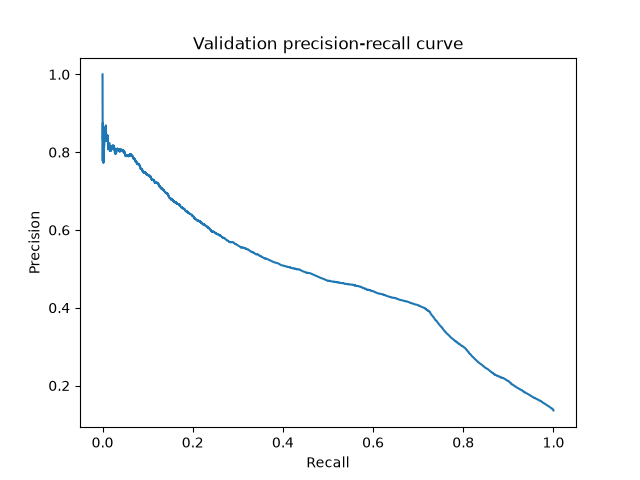

xgboost MLflow run: 0aeac7b9725849fead64c77b5705b0bb


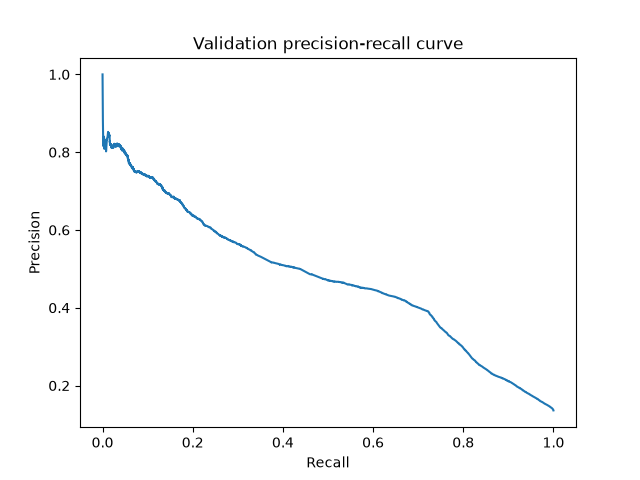

lightgbm MLflow run: 91db7fa7fc694ce3952c515cc386405a


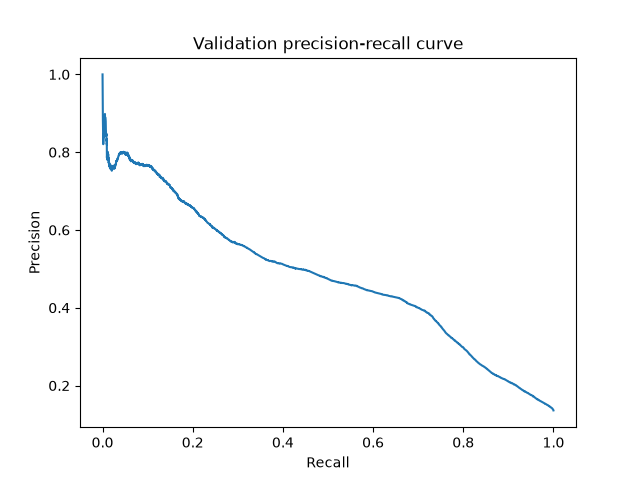

hist_gradient_boosting MLflow run: f6e01df787d14eb3b7271f1dc047711a


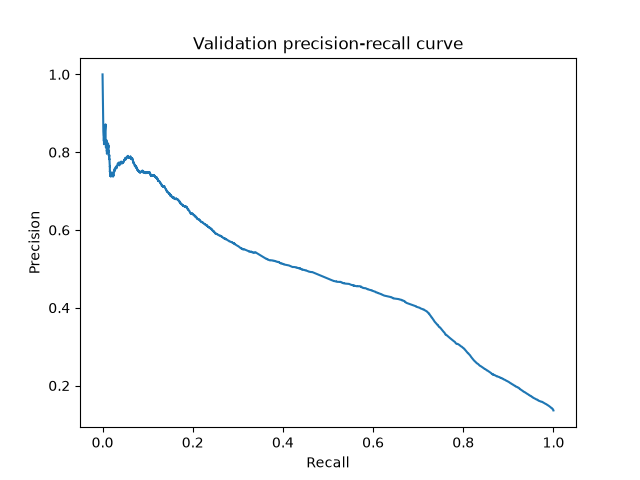

logistic_regression MLflow run: d7b938d37c054cea9f9a8df611bdecfd


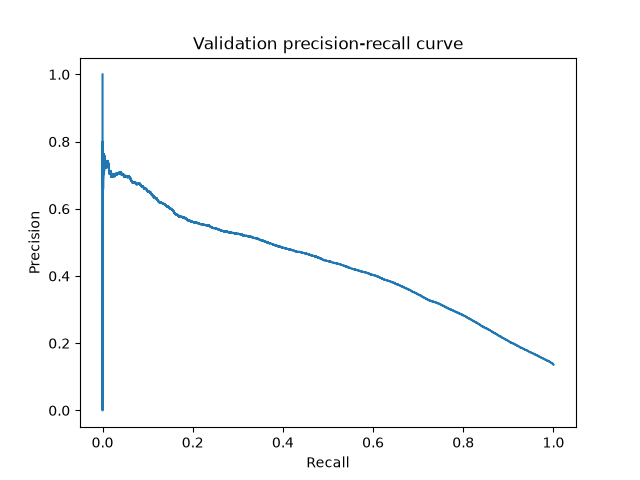

In [41]:
import mlflow

for result in results:
    print(result["model"], "MLflow run:", result["run_id"])
    curve = mlflow.artifacts.download_artifacts(run_id=result["run_id"], artifact_path="precision_recall.png")
    display(Image(filename=curve))

## PBI 06 — Historical training-only hyperparameter search

The recorded search used three configurations per algorithm and two expanding whole-date folds inside training. Preprocessing and class weights were fitted on each inner training fold. The original trial results below are loaded from MLflow; no search is run.

In [42]:
print("Loading the previously selected initial tuned models; no search is run.")
tuned_results = groups["tuned"]

Loading the previously selected initial tuned models; no search is run.


In [43]:
print("Inner training-fold results (selection evidence):")
display(inner_trials[["model", "candidate", "fold", "inner_f1", "parameters", "weight_strength", "run_id"]])
print("Selected changes and inner mean F1:")
selected = pd.DataFrame(tuned_results)[["model", "selected_changes", "weight_strength", "inner_mean_f1"]]
display(selected)
print("Complete fitted model parameters:")
display(pd.DataFrame({result["model"]: result["parameters"] for result in tuned_results}).T)

Inner training-fold results (selection evidence):


,model,candidate,fold,inner_f1,parameters,weight_strength,run_id
17,catboost,1,1,0.335769,{},1.0,3eb7307f00ff42a8b668e7690feb4ded
16,catboost,2,1,0.334936,"{'iterations': 120, 'depth': 6, 'l2_leaf_reg': 4}",1.0,444035f1baf442049eeea4ad8e3ffa9b
15,catboost,3,1,0.384911,"{'iterations': 120, 'depth': 5, 'learning_rate...",0.5,dd9fa187d20e440d92a16fe7e74ce8c7
14,lightgbm,1,1,0.337042,{},1.0,b19afddaa1734d3cabf5bee9ac4ede75
13,lightgbm,2,1,0.336139,"{'n_estimators': 120, 'num_leaves': 15, 'min_c...",1.0,b552138d4934401482b9b588022e2bed
12,lightgbm,3,1,0.382198,"{'n_estimators': 120, 'num_leaves': 15, 'learn...",0.5,f10d9ad6ae2c4f0c917aade90cf2a463
11,random_forest,1,1,0.337892,{},1.0,e1de062b3b7d4241a8538ac3af41a4af
10,random_forest,2,1,0.343786,"{'n_estimators': 40, 'max_depth': 16, 'min_sam...",1.0,2f4f323a0a384a288a0632117d7ce7df
9,random_forest,3,1,0.385893,"{'n_estimators': 40, 'max_depth': 12, 'min_sam...",0.5,66b7e2d383ed4290a26ce0c8d7ccca74
8,catboost,1,2,0.343496,{},1.0,0acb3148d0d84710b9f6a417278202f1


Selected changes and inner mean F1:


,model,selected_changes,weight_strength,inner_mean_f1
0,lightgbm,"{'n_estimators': 120, 'num_leaves': 15, 'learn...",0.5,0.384113
1,catboost,"{'iterations': 120, 'depth': 5, 'learning_rate...",0.5,0.385747
2,random_forest,"{'n_estimators': 40, 'max_depth': 12, 'min_sam...",0.5,0.383603


Complete fitted model parameters:


,boosting_type,class_weight,colsample_bytree,importance_type,learning_rate,max_depth,min_child_samples,min_child_weight,min_split_gain,n_estimators,...,max_features,max_leaf_nodes,max_samples,min_impurity_decrease,min_samples_leaf,min_samples_split,min_weight_fraction_leaf,monotonic_cst,oob_score,warm_start
lightgbm,gbdt,None,1.0,split,0.08,-1,20,0.001,0.0,120,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
catboost,NaN,NaN,NaN,NaN,0.08,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
random_forest,NaN,None,NaN,NaN,NaN,12,NaN,NaN,NaN,40,...,sqrt,None,None,0.0,40,2,0.0,None,False,False


### Baseline versus tuned — outer validation

Each recorded tuned model was refitted on the complete training partition after its parameters were selected. The table includes F1, precision, recall, AP, ROC-AUC, accuracy, false-positive rate, confusion counts and timings. Repeatedly examining this validation set can overstate confidence in a model choice.

In [44]:
tuned_comparison = pd.DataFrame(tuned_results).drop(columns=["parameters", "selected_changes"])
baseline_and_tuned = pd.concat([comparison, tuned_comparison], ignore_index=True, sort=False)
baseline_and_tuned = baseline_and_tuned.sort_values("f1", ascending=False)
display(baseline_and_tuned)

,model,version,threshold,f1,precision,recall,average_precision,roc_auc,accuracy,tn,fp,fn,tp,false_positive_rate,training_seconds,prediction_seconds,run_id,weight_strength,inner_mean_f1
6,lightgbm,tuned,0.5,0.496340,0.462281,0.535816,0.482796,0.822626,0.851936,112935,12303,9163,10577,0.098237,0.705293,0.080066,47e6724a7679483dab87550bbc5f5f9c,0.5,0.384113
7,catboost,tuned,0.5,0.494060,0.464405,0.527761,0.473703,0.822585,0.852826,113223,12015,9322,10418,0.095937,2.798244,0.006262,b69a66a13c2c470aaf2cda872af3a52f,0.5,0.385747
8,random_forest,tuned,0.5,0.488546,0.469355,0.509372,0.479682,0.824628,0.854785,113870,11368,9685,10055,0.090771,5.822176,0.050311,e85dff34a5424913ac43dba5f14dcbc1,0.5,0.383603
0,catboost,baseline,0.5,0.444263,0.309565,0.786474,0.468765,0.822419,0.732090,90612,34626,4215,15525,0.276482,1.840751,0.005115,59a72ead8d34483ea1f82644b4511d55,NaN,NaN
1,random_forest,baseline,0.5,0.441067,0.305481,0.793060,0.475494,0.823670,0.726324,89646,35592,4085,15655,0.284195,2.372368,0.036476,25bb1427c3b647668c8037fc761e88a9,NaN,NaN
2,xgboost,baseline,0.5,0.440974,0.305490,0.792401,0.475565,0.823769,0.726448,89677,35561,4098,15642,0.283947,0.638068,0.037345,0aeac7b9725849fead64c77b5705b0bb,NaN,NaN
3,lightgbm,baseline,0.5,0.440884,0.305396,0.792452,0.478404,0.824276,0.726331,89659,35579,4097,15643,0.284091,0.603209,0.064812,91db7fa7fc694ce3952c515cc386405a,NaN,NaN
4,hist_gradient_boosting,baseline,0.5,0.439756,0.304465,0.791439,0.473654,0.822623,0.725427,89548,35690,4117,15623,0.284977,2.386679,0.068264,f6e01df787d14eb3b7271f1dc047711a,NaN,NaN
5,logistic_regression,baseline,0.5,0.424602,0.290647,0.787589,0.434044,0.810814,0.709356,87294,37944,4193,15547,0.302975,2.452170,0.001048,d7b938d37c054cea9f9a8df611bdecfd,NaN,NaN


lightgbm selected parameters: {'n_estimators': 120, 'num_leaves': 15, 'learning_rate': 0.08, 'reg_lambda': 5} weight strength: 0.5


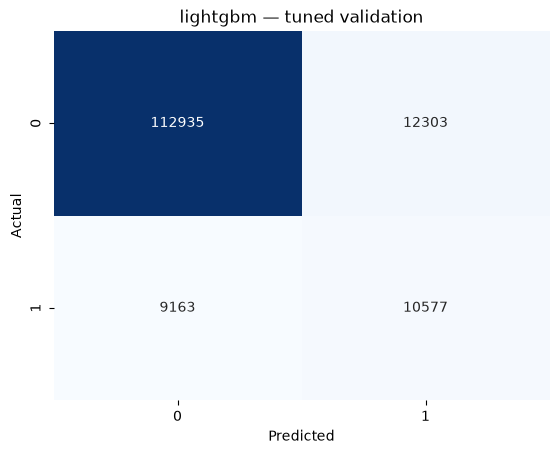

catboost selected parameters: {'iterations': 120, 'depth': 5, 'learning_rate': 0.08, 'l2_leaf_reg': 5} weight strength: 0.5


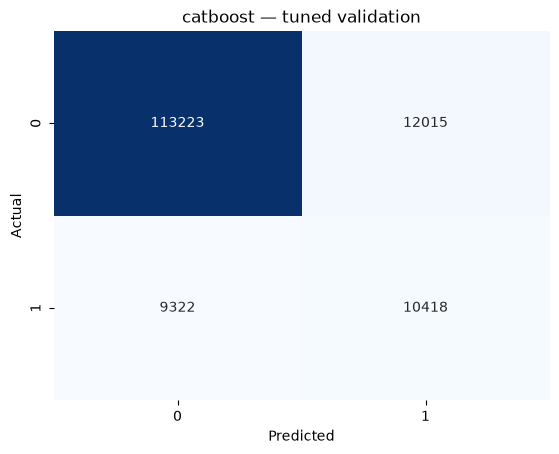

random_forest selected parameters: {'n_estimators': 40, 'max_depth': 12, 'min_samples_leaf': 40, 'class_weight': None} weight strength: 0.5


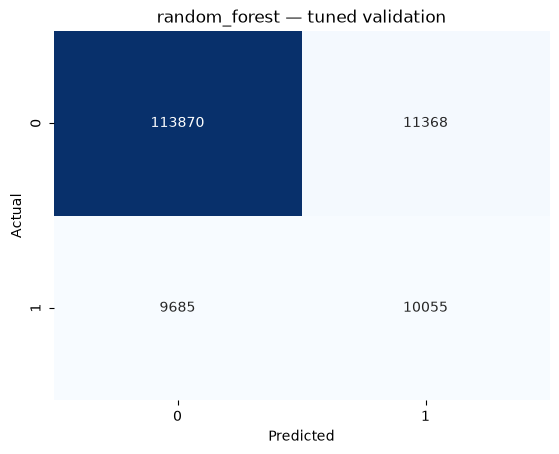

In [45]:
for result in tuned_results:
    print(result["model"], "selected parameters:", result["selected_changes"],
          "weight strength:", result["weight_strength"])
    matrix = [[result["tn"], result["fp"]], [result["fn"], result["tp"]]]
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(result["model"] + " — tuned validation")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

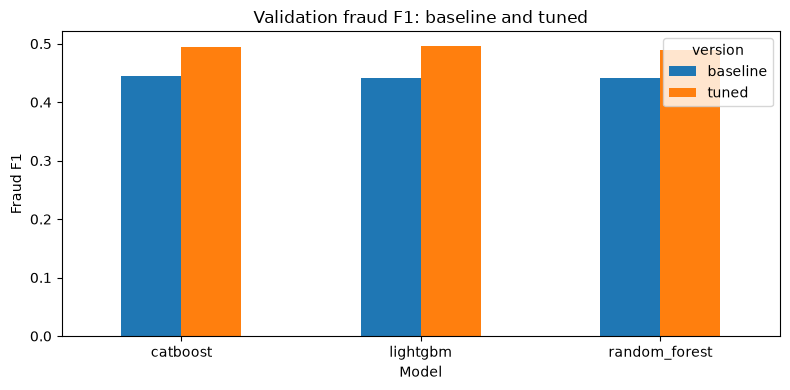

Tuned MLflow run IDs:


,model,run_id
0,lightgbm,47e6724a7679483dab87550bbc5f5f9c
1,catboost,b69a66a13c2c470aaf2cda872af3a52f
2,random_forest,e85dff34a5424913ac43dba5f14dcbc1


In [46]:
model_names = ["catboost", "lightgbm", "random_forest"]
selected_comparison = baseline_and_tuned[baseline_and_tuned["model"].isin(model_names)]
selected_comparison.pivot(index="model", columns="version", values="f1").plot.bar(figsize=(8, 4))
plt.title("Validation fraud F1: baseline and tuned")
plt.ylabel("Fraud F1")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print("Tuned MLflow run IDs:")
display(pd.DataFrame(tuned_results)[["model", "run_id"]])

## PBI 06 — Historical advanced hyperparameter search

The previous advanced search evaluated 20 configurations per model in two chronological training-only folds. Its 120 trial results and selected models are loaded from the frozen local evidence. Run All never reruns a search.

In [47]:
print("Loading the three recorded advanced models and 120 historical trials; no search is run.")
advanced_results = groups["advanced_tuned"]

Loading the three recorded advanced models and 120 historical trials; no search is run.


In [48]:
print("All 120 chronological inner-fold results:")
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(advanced_trials[["model", "candidate", "fold", "inner_f1", "parameters", "weight_strength", "run_id"]])
print("Selected advanced parameters:")
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(advanced_results)[["model", "selected_changes", "weight_strength", "inner_mean_f1", "run_id"]])

All 120 chronological inner-fold results:


,model,candidate,fold,inner_f1,parameters,weight_strength,run_id
119,catboost,1,1,0.384911,"{'iterations': 120, 'depth': 5, 'learning_rate': 0.08, 'l2_leaf_reg': 5}",0.50,e4b7e067638a4b8abd77d31be84a5646
118,catboost,2,1,0.332952,"{'subsample': 1.0, 'learning_rate': 0.04, 'l2_leaf_reg': 3, 'iterations': 120, 'depth': 6, 'bootstrap_type': 'Bernoulli'}",1.00,b7206ae267fe4de090db9d50d16634cb
117,catboost,3,1,0.383796,"{'subsample': 1.0, 'learning_rate': 0.12, 'l2_leaf_reg': 5, 'iterations': 80, 'depth': 4, 'bootstrap_type': 'Bernoulli'}",0.75,dfd9235409cf42728f444460cff07c35
116,catboost,4,1,0.334163,"{'subsample': 0.7, 'learning_rate': 0.12, 'l2_leaf_reg': 10, 'iterations': 120, 'depth': 6, 'bootstrap_type': 'Bernoulli'}",1.00,4abea5d9b6894b98b6352e0f33af0aef
115,catboost,5,1,0.383841,"{'subsample': 0.85, 'learning_rate': 0.08, 'l2_leaf_reg': 5, 'iterations': 120, 'depth': 5, 'bootstrap_type': 'Bernoulli'}",0.50,6040ace7dd9240f5bc976b5cef3dbe9f
114,catboost,6,1,0.291189,"{'subsample': 1.0, 'learning_rate': 0.12, 'l2_leaf_reg': 10, 'iterations': 160, 'depth': 5, 'bootstrap_type': 'Bernoulli'}",0.25,58d4bf9c0335447492ff3c2a3d9bfb24
113,catboost,7,1,0.334909,"{'subsample': 0.85, 'learning_rate': 0.12, 'l2_leaf_reg': 10, 'iterations': 120, 'depth': 5, 'bootstrap_type': 'Bernoulli'}",1.00,9542117e3b594598b5b6447926efee9e
112,catboost,8,1,0.384529,"{'subsample': 0.7, 'learning_rate': 0.12, 'l2_leaf_reg': 5, 'iterations': 160, 'depth': 4, 'bootstrap_type': 'Bernoulli'}",0.50,7dbf8546ceb34c06a4ccd226b345bd0d
111,catboost,9,1,0.290591,"{'subsample': 0.85, 'learning_rate': 0.12, 'l2_leaf_reg': 5, 'iterations': 160, 'depth': 4, 'bootstrap_type': 'Bernoulli'}",0.25,535df1281c784bd6ba6190be7393a80e
110,catboost,10,1,0.335817,"{'subsample': 0.85, 'learning_rate': 0.12, 'l2_leaf_reg': 10, 'iterations': 160, 'depth': 6, 'bootstrap_type': 'Bernoulli'}",1.00,3258ec467c144b48bfde73b807caf506


Selected advanced parameters:


,model,selected_changes,weight_strength,inner_mean_f1,run_id
0,lightgbm,"{'subsample': 1.0, 'reg_lambda': 10, 'num_leaves': 15, 'n_estimators': 120, 'min_child_samples': 50, 'learning_rate': 0.04, 'colsample_bytree': 0.7, 'subsample_freq': 1}",0.75,0.387087,d6e45399a8934446aadeb01caddd7849
1,catboost,"{'subsample': 0.7, 'learning_rate': 0.12, 'l2_leaf_reg': 3, 'iterations': 160, 'depth': 6, 'bootstrap_type': 'Bernoulli'}",0.50,0.387966,12c49c06191b47e2898a126c9f722e11
2,random_forest,"{'n_estimators': 30, 'min_samples_leaf': 50, 'max_samples': 0.85, 'max_features': 1.0, 'max_depth': 10, 'class_weight': None}",0.50,0.388580,a8998c12d8004c8e9f47db017db1f2f5


### Combined validation leaderboard

This compares all six baseline versions, the three earlier tuned versions and the three advanced versions. Candidate selection used training-only inner-fold F1; these results are the subsequent outer-validation comparison. Do not select thresholds or evaluate the test set here.

In [49]:
advanced_comparison = pd.DataFrame(advanced_results).drop(columns=["parameters", "selected_changes"])
leaderboard = pd.concat([baseline_and_tuned, advanced_comparison], ignore_index=True, sort=False)
leaderboard = leaderboard.sort_values("f1", ascending=False).reset_index(drop=True)
display(leaderboard)

,model,version,threshold,f1,precision,recall,average_precision,roc_auc,accuracy,tn,fp,fn,tp,false_positive_rate,training_seconds,prediction_seconds,run_id,weight_strength,inner_mean_f1
0,lightgbm,advanced_tuned,0.5,0.510328,0.405238,0.689007,0.468303,0.821682,0.819966,105276,19962,6139,13601,0.159393,0.722481,0.081219,d6e45399a8934446aadeb01caddd7849,0.75,0.387087
1,catboost,advanced_tuned,0.5,0.500691,0.459002,0.550709,0.481255,0.825009,0.850446,112425,12813,8869,10871,0.102309,3.173624,0.006498,12c49c06191b47e2898a126c9f722e11,0.50,0.387966
2,lightgbm,tuned,0.5,0.496340,0.462281,0.535816,0.482796,0.822626,0.851936,112935,12303,9163,10577,0.098237,0.705293,0.080066,47e6724a7679483dab87550bbc5f5f9c,0.50,0.384113
3,random_forest,advanced_tuned,0.5,0.495097,0.454634,0.543465,0.477705,0.822388,0.849074,112369,12869,9012,10728,0.102756,9.999244,0.051045,a8998c12d8004c8e9f47db017db1f2f5,0.50,0.388580
4,catboost,tuned,0.5,0.494060,0.464405,0.527761,0.473703,0.822585,0.852826,113223,12015,9322,10418,0.095937,2.798244,0.006262,b69a66a13c2c470aaf2cda872af3a52f,0.50,0.385747
5,random_forest,tuned,0.5,0.488546,0.469355,0.509372,0.479682,0.824628,0.854785,113870,11368,9685,10055,0.090771,5.822176,0.050311,e85dff34a5424913ac43dba5f14dcbc1,0.50,0.383603
6,catboost,baseline,0.5,0.444263,0.309565,0.786474,0.468765,0.822419,0.732090,90612,34626,4215,15525,0.276482,1.840751,0.005115,59a72ead8d34483ea1f82644b4511d55,NaN,NaN
7,random_forest,baseline,0.5,0.441067,0.305481,0.793060,0.475494,0.823670,0.726324,89646,35592,4085,15655,0.284195,2.372368,0.036476,25bb1427c3b647668c8037fc761e88a9,NaN,NaN
8,xgboost,baseline,0.5,0.440974,0.305490,0.792401,0.475565,0.823769,0.726448,89677,35561,4098,15642,0.283947,0.638068,0.037345,0aeac7b9725849fead64c77b5705b0bb,NaN,NaN
9,lightgbm,baseline,0.5,0.440884,0.305396,0.792452,0.478404,0.824276,0.726331,89659,35579,4097,15643,0.284091,0.603209,0.064812,91db7fa7fc694ce3952c515cc386405a,NaN,NaN


lightgbm selected parameters: {'subsample': 1.0, 'reg_lambda': 10, 'num_leaves': 15, 'n_estimators': 120, 'min_child_samples': 50, 'learning_rate': 0.04, 'colsample_bytree': 0.7, 'subsample_freq': 1} weight strength: 0.75


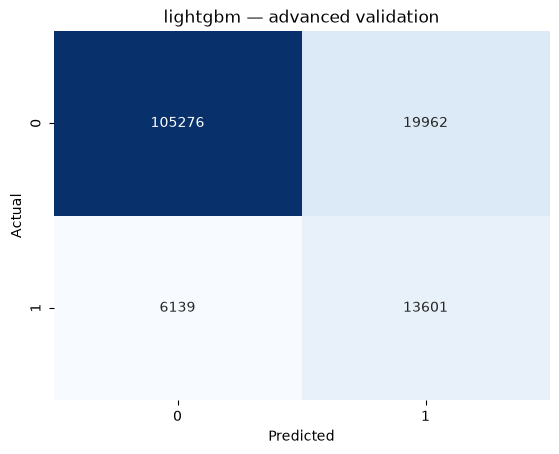

catboost selected parameters: {'subsample': 0.7, 'learning_rate': 0.12, 'l2_leaf_reg': 3, 'iterations': 160, 'depth': 6, 'bootstrap_type': 'Bernoulli'} weight strength: 0.5


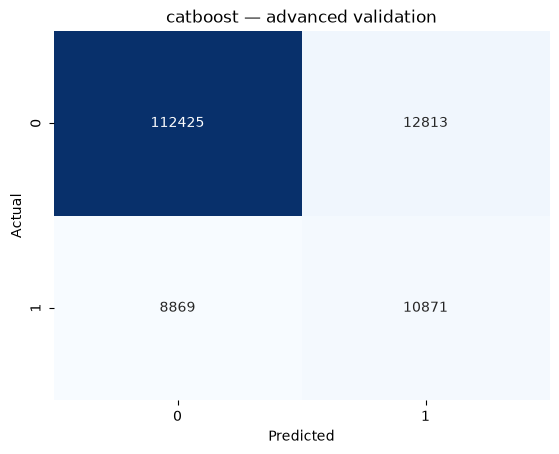

random_forest selected parameters: {'n_estimators': 30, 'min_samples_leaf': 50, 'max_samples': 0.85, 'max_features': 1.0, 'max_depth': 10, 'class_weight': None} weight strength: 0.5


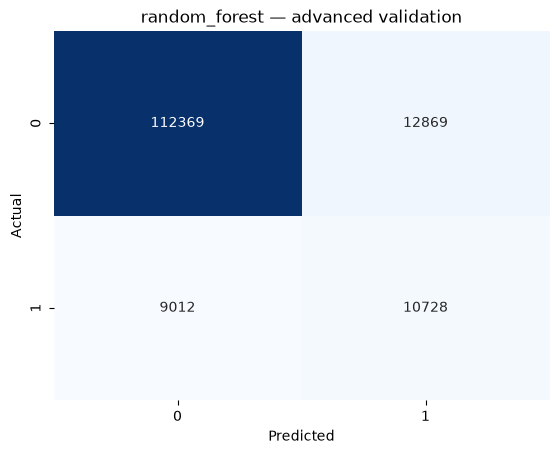

In [50]:
for result in advanced_results:
    print(result["model"], "selected parameters:", result["selected_changes"],
          "weight strength:", result["weight_strength"])
    matrix = [[result["tn"], result["fp"]], [result["fn"], result["tp"]]]
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(result["model"] + " — advanced validation")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

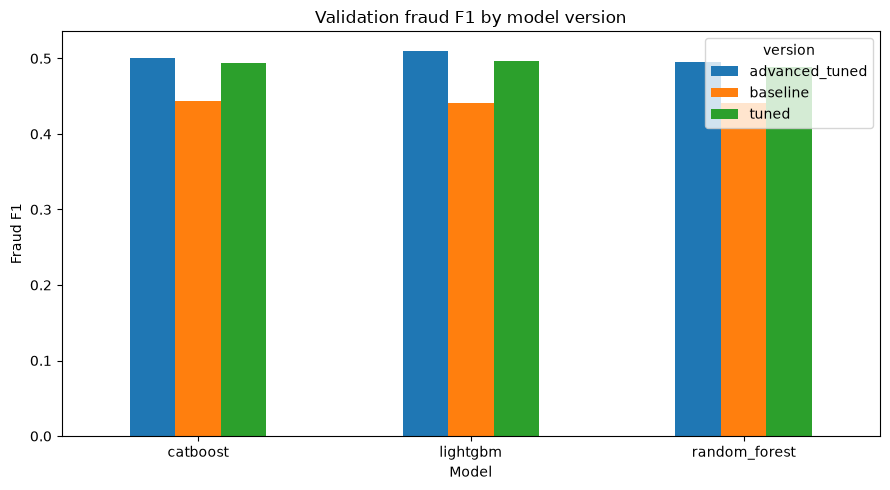

In [51]:
top_models = ["catboost", "lightgbm", "random_forest"]
versions = leaderboard[leaderboard["model"].isin(top_models)]
versions.pivot(index="model", columns="version", values="f1").plot.bar(figsize=(9, 5))
plt.title("Validation fraud F1 by model version")
plt.xlabel("Model")
plt.ylabel("Fraud F1")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## PBI 06 — Historical training-only threshold selection

Each fixed advanced model was refitted on two chronological inner-training folds. A threshold maximizing pooled out-of-fold fraud F1 was selected without using outer-validation or test data. The same folds also informed hyperparameter selection, so training-only F1 can be optimistic. These are the original logged results; no threshold search is run.

In [52]:
print("Loading the recorded training-only thresholds; no threshold search is run.")
threshold_results = groups["threshold_optimized"]
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(threshold_results)[["model", "threshold", "oof_f1", "oof_rows", "selection_seconds", "run_id"]])

Loading the recorded training-only thresholds; no threshold search is run.


,model,threshold,oof_f1,oof_rows,selection_seconds,run_id
0,catboost,0.456841,0.391394,269125,5.396035,ad724329187b4f99a3845cf8abadb0aa
1,lightgbm,0.558408,0.390504,269125,2.148460,fad3c3f16b9a4476aecab034eb002831
2,random_forest,0.461245,0.389879,269125,13.336112,740d1cfc49be43808a6ca270d4fffdfe


### Complete validation leaderboard

The table includes all six baselines, three initial tuned models, three advanced models at 0.5 and three threshold-optimized versions. Thresholds were selected from training folds; validation is shown for comparison only. AP and ROC-AUC use model probabilities and do not depend on the classification threshold.

In [53]:
threshold_comparison = pd.DataFrame(threshold_results).drop(columns=["parameters", "selected_changes"])
full_leaderboard = pd.concat([leaderboard, threshold_comparison], ignore_index=True, sort=False)
full_leaderboard = full_leaderboard.sort_values("f1", ascending=False).reset_index(drop=True)
with pd.option_context("display.max_columns", None, "display.width", None):
    display(full_leaderboard)

,model,version,threshold,f1,precision,recall,average_precision,roc_auc,accuracy,tn,fp,fn,tp,false_positive_rate,training_seconds,prediction_seconds,run_id,weight_strength,inner_mean_f1,oof_f1,oof_rows,selection_seconds
0,catboost,threshold_optimized,0.456841,0.511540,0.438008,0.614742,0.481255,0.825009,0.840148,109668,15570,7605,12135,0.124323,3.173624,0.006252,ad724329187b4f99a3845cf8abadb0aa,0.50,NaN,0.391394,269125.0,5.396035
1,lightgbm,advanced_tuned,0.500000,0.510328,0.405238,0.689007,0.468303,0.821682,0.819966,105276,19962,6139,13601,0.159393,0.722481,0.081219,d6e45399a8934446aadeb01caddd7849,0.75,0.387087,NaN,NaN,NaN
2,lightgbm,threshold_optimized,0.558408,0.503650,0.444949,0.580193,0.468303,0.821682,0.844294,110951,14287,8287,11453,0.114079,0.722481,0.080894,fad3c3f16b9a4476aecab034eb002831,0.75,NaN,0.390504,269125.0,2.148460
3,random_forest,threshold_optimized,0.461245,0.503244,0.451848,0.567832,0.477705,0.822388,0.847363,111640,13598,8531,11209,0.108577,9.999244,0.051096,740d1cfc49be43808a6ca270d4fffdfe,0.50,NaN,0.389879,269125.0,13.336112
4,catboost,advanced_tuned,0.500000,0.500691,0.459002,0.550709,0.481255,0.825009,0.850446,112425,12813,8869,10871,0.102309,3.173624,0.006498,12c49c06191b47e2898a126c9f722e11,0.50,0.387966,NaN,NaN,NaN
5,lightgbm,tuned,0.500000,0.496340,0.462281,0.535816,0.482796,0.822626,0.851936,112935,12303,9163,10577,0.098237,0.705293,0.080066,47e6724a7679483dab87550bbc5f5f9c,0.50,0.384113,NaN,NaN,NaN
6,random_forest,advanced_tuned,0.500000,0.495097,0.454634,0.543465,0.477705,0.822388,0.849074,112369,12869,9012,10728,0.102756,9.999244,0.051045,a8998c12d8004c8e9f47db017db1f2f5,0.50,0.388580,NaN,NaN,NaN
7,catboost,tuned,0.500000,0.494060,0.464405,0.527761,0.473703,0.822585,0.852826,113223,12015,9322,10418,0.095937,2.798244,0.006262,b69a66a13c2c470aaf2cda872af3a52f,0.50,0.385747,NaN,NaN,NaN
8,random_forest,tuned,0.500000,0.488546,0.469355,0.509372,0.479682,0.824628,0.854785,113870,11368,9685,10055,0.090771,5.822176,0.050311,e85dff34a5424913ac43dba5f14dcbc1,0.50,0.383603,NaN,NaN,NaN
9,catboost,baseline,0.500000,0.444263,0.309565,0.786474,0.468765,0.822419,0.732090,90612,34626,4215,15525,0.276482,1.840751,0.005115,59a72ead8d34483ea1f82644b4511d55,NaN,NaN,NaN,NaN,NaN


catboost threshold: 0.456841 validation F1: 0.5115


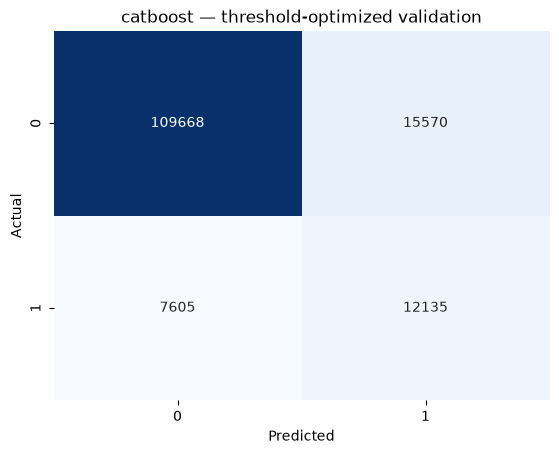

lightgbm threshold: 0.558408 validation F1: 0.5036


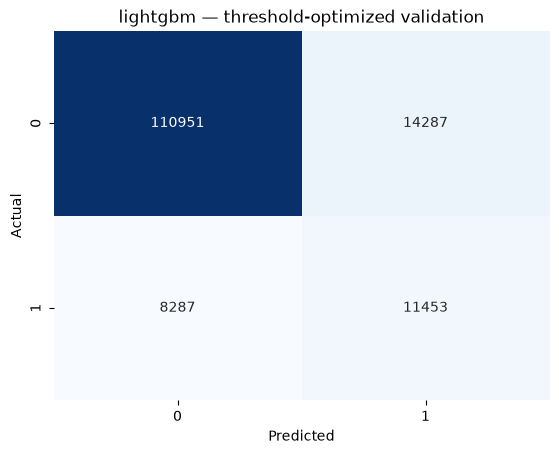

random_forest threshold: 0.461245 validation F1: 0.5032


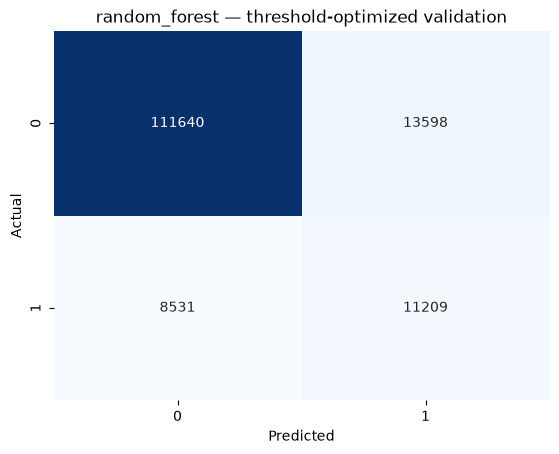

In [54]:
for result in threshold_results:
    print(result["model"], "threshold:", round(result["threshold"], 6),
          "validation F1:", round(result["f1"], 4))
    matrix = [[result["tn"], result["fp"]], [result["fn"], result["tp"]]]
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(result["model"] + " — threshold-optimized validation")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

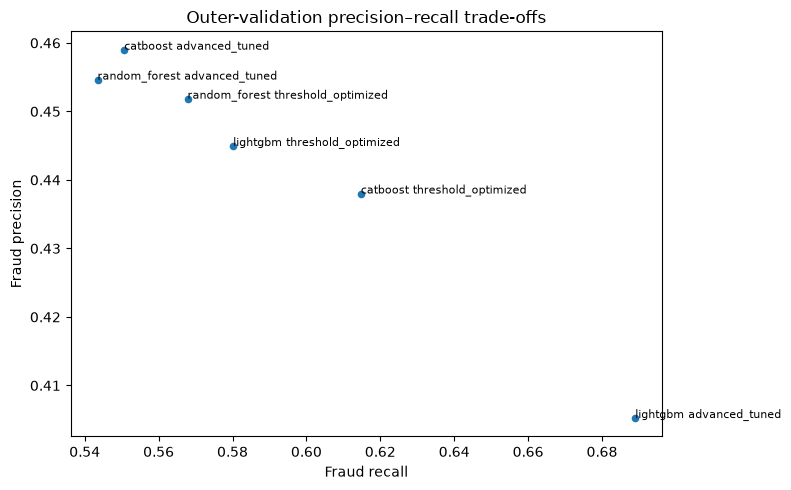

In [55]:
threshold_versions = full_leaderboard[full_leaderboard["version"].isin(["advanced_tuned", "threshold_optimized"])]
threshold_versions.plot.scatter(x="recall", y="precision", figsize=(8, 5))
for _, row in threshold_versions.iterrows():
    plt.annotate(row["model"] + " " + row["version"], (row["recall"], row["precision"]), fontsize=8)
plt.title("Outer-validation precision–recall trade-offs")
plt.xlabel("Fraud recall")
plt.ylabel("Fraud precision")
plt.tight_layout()
plt.show()

## PBI 10 integration and remaining work

`src.train_hq.train_selected_models` independently refits the fixed CatBoost and LightGBM configurations on supplied PBI 03 training data and evaluates validation with the previously selected thresholds. It performs no search and does not accept test data. See `README.md` for its signature and example.

Local MLflow evidence is not shared AWS MLflow evidence. Point-in-time-safe customer features, shared service verification, PBI 10 integration and the end-to-end three-minute demonstration remain open. The historical full-data EDA had already examined labels before the holdout was created.

### PBI 06 acceptance status

- **Local evidence complete:** reproducible split and fraud metrics; comparison and documented improvements; independently callable fixed-model retraining interface.
- **Partial:** customer features are excluded until point-in-time safety is established.
- **Blocked:** the issue requires artifacts in shared AWS MLflow, which has not been verified. PBI 10 owner integration and the end-to-end demo also remain pending.

Local verification runs: CatBoost `a32ff6b4cdae4476ac3be5b79e0ed56a`; LightGBM `9d929ed60986442c85394bf37444ca22`. Their models, preprocessors and thresholds were reloaded and checked against validation. No champion is registered.